In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import make_classification

In [15]:
X,y = make_classification(n_samples = 1000, n_features = 2, n_classes = 2, n_clusters_per_class = 1, n_redundant = 0)

In [16]:
X

array([[ 2.4789667 , -0.05136012],
       [-1.50900058, -0.45430109],
       [ 0.89152689,  1.30721891],
       ...,
       [ 1.94763447,  0.54981458],
       [-0.25395262, -1.83054284],
       [ 1.54802927,  0.47329586]], shape=(1000, 2))

In [17]:
pd.DataFrame(X)[0]

0      2.478967
1     -1.509001
2      0.891527
3     -0.367337
4      1.628936
         ...   
995   -0.044740
996    0.454971
997    1.947634
998   -0.253953
999    1.548029
Name: 0, Length: 1000, dtype: float64

<Axes: xlabel='0', ylabel='1'>

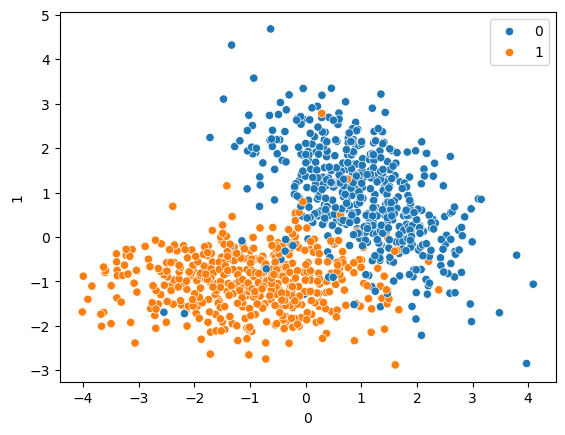

In [18]:
sns.scatterplot(x=pd.DataFrame(X)[0], y=pd.DataFrame(X)[1], hue=y)

In [19]:
from sklearn.model_selection import train_test_split

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.25, random_state = 10)

In [21]:
from sklearn.svm import SVC

In [22]:
svc = SVC(kernel = 'linear')

In [23]:
svc.fit(X_train, y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [54]:
svc.coef_

array([[-0.33813272,  1.56134874]])

In [24]:
y_pred = svc.predict(X_test)

In [25]:
from sklearn.metrics import classification_report, confusion_matrix 

In [26]:
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

[[118  10]
 [  6 116]]
              precision    recall  f1-score   support

           0       0.95      0.92      0.94       128
           1       0.92      0.95      0.94       122

    accuracy                           0.94       250
   macro avg       0.94      0.94      0.94       250
weighted avg       0.94      0.94      0.94       250



## RBF Kernal


In [30]:
X,y = make_classification(n_samples = 1000, n_features = 2, n_classes = 2, n_clusters_per_class = 2, n_redundant = 0)

In [31]:
X

array([[ 1.64072712,  1.55101826],
       [ 0.84775129,  1.02822636],
       [-1.20573154,  0.97104022],
       ...,
       [ 1.26128234, -1.1205334 ],
       [-0.07428593,  0.35742926],
       [-0.34091405, -1.04897122]], shape=(1000, 2))

<Axes: xlabel='0', ylabel='1'>

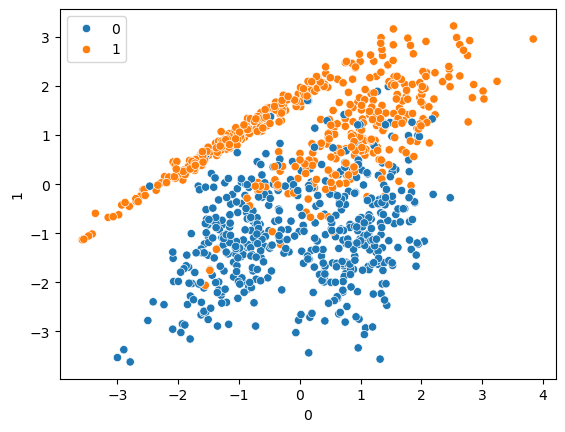

In [32]:
sns.scatterplot(x=pd.DataFrame(X)[0], y=pd.DataFrame(X)[1], hue=y)

In [33]:
from sklearn.model_selection import train_test_split

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.25, random_state = 10)

In [35]:
from sklearn.svm import SVC

In [41]:
rbf = SVC(kernel = 'rbf')

In [42]:
rbf.fit(X_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [44]:
y_pred1 = rbf.predict(X_test)

In [39]:
from sklearn.metrics import classification_report, confusion_matrix 

In [45]:
print(confusion_matrix(y_test,y_pred1))
print(classification_report(y_test,y_pred1))

[[108  16]
 [  9 117]]
              precision    recall  f1-score   support

           0       0.92      0.87      0.90       124
           1       0.88      0.93      0.90       126

    accuracy                           0.90       250
   macro avg       0.90      0.90      0.90       250
weighted avg       0.90      0.90      0.90       250



In [46]:
polynomial = SVC(kernel = 'poly')
polynomial.fit(X_train, y_train)
y_pred2 = polynomial.predict(X_test)
print(classification_report(y_test,y_pred2))
print(confusion_matrix(y_test,y_pred2))

              precision    recall  f1-score   support

           0       0.83      0.94      0.88       124
           1       0.94      0.81      0.87       126

    accuracy                           0.88       250
   macro avg       0.88      0.88      0.88       250
weighted avg       0.88      0.88      0.88       250

[[117   7]
 [ 24 102]]


In [47]:
sigmoid = SVC(kernel = 'sigmoid')
sigmoid.fit(X_train, y_train)
y_pred3 = sigmoid.predict(X_test)
print(classification_report(y_test,y_pred3))
print(confusion_matrix(y_test,y_pred3))

              precision    recall  f1-score   support

           0       0.78      0.76      0.77       124
           1       0.77      0.79      0.78       126

    accuracy                           0.77       250
   macro avg       0.77      0.77      0.77       250
weighted avg       0.77      0.77      0.77       250

[[94 30]
 [27 99]]


In [53]:
sigmoid.intercept_

array([0.09676258])

## Hyperparameter Tuning with SVC

In [48]:
from sklearn.model_selection import GridSearchCV

param_grid = {'C': [0.1, 1, 10, 100, 1000],
            'gamma' : [1, 0.1, 0.01, 0.001, 0.0001],
            'kernel' : ['rbf']
}

In [49]:
grid = GridSearchCV(SVC(), param_grid= param_grid, cv =5, verbose=3, refit = True)

In [50]:
grid.fit(X_train, y_train)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
[CV 1/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.933 total time=   0.0s
[CV 2/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.887 total time=   0.0s
[CV 3/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.847 total time=   0.0s
[CV 4/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.880 total time=   0.0s
[CV 5/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.913 total time=   0.0s
[CV 1/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.940 total time=   0.0s
[CV 2/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.873 total time=   0.0s
[CV 3/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.860 total time=   0.0s
[CV 4/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.853 total time=   0.0s
[CV 5/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.907 total time=   0.0s
[CV 1/5] END .....C=0.1, gamma=0.01, kernel=rbf;, score=0.887 total time=   0.0s
[CV 2/5] END .....C=0.1, gamma=0.01, kernel=rbf

,estimator,SVC()
,param_grid,"{'C': [0.1, 1, ...], 'gamma': [1, 0.1, ...], 'kernel': ['rbf']}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,1000


In [51]:
grid.best_params_

{'C': 1000, 'gamma': 0.1, 'kernel': 'rbf'}

In [52]:
y_pred4 = grid.predict(X_test)
print(confusion_matrix(y_test,y_pred4))
print(classification_report(y_test,y_pred4))

[[109  15]
 [  9 117]]
              precision    recall  f1-score   support

           0       0.92      0.88      0.90       124
           1       0.89      0.93      0.91       126

    accuracy                           0.90       250
   macro avg       0.91      0.90      0.90       250
weighted avg       0.90      0.90      0.90       250

